# B01-GN — GMM trên RFM (log1p + Standard + PCA 90%)

Thí nghiệm **B01-GN** (người chạy: Nguyên) theo chiến lược model. So với A01, **chỉ thêm `log1p` trước khi scale**: làm sạch → RFM → `log1p` → StandardScaler → PCA giữ ≥ 90% phương sai → GMM. Đây là nhánh chính của nhóm B; B02, B03, B04 so với kết quả này.

Cài đặt GMM, lưới `k × covariance_type` và quy tắc chọn giữ nguyên như thư mục GMM của Thuận để các kết quả so sánh được. Mã "GN" trong bảng chiến lược được hiểu là GMM (Gaussian Mixture).

## Params

In [1]:
FEATURES = ["Recency", "Frequency", "Monetary"]
PCA_VAR = 0.90                    # giữ ít nhất 90% phương sai (giống A01)
RANDOM_STATE = 42                 # từ đây đến MIN_CLUSTER_FRAC: giống GMM của Thuận
N_INIT = 10
MAX_ITER = 300
TOL = 1e-3
REG_COVAR = 1e-6
INIT_PARAMS = "kmeans"
K_RANGE = range(2, 11)
COV_TYPES = ["full", "tied", "diag", "spherical"]
MIN_CLUSTER_FRAC = 0.01           # điều kiện chọn: mỗi cụm >= 1% số khách

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

warnings.filterwarnings("ignore", category=UserWarning)

def find(rel):
    # Tự tìm file trong repo, không phụ thuộc nơi mở notebook
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01-DB, A02-KM, GMM của Thuận), không sao chép thêm
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()   # log1p cần X >= 0
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95
std,99.98,7.64,8441.89
min,1.00,1.00,2.90
25%,18.00,1.00,301.52
50%,51.00,2.00,657.90
75%,143.00,5.00,1624.10
max,374.00,206.00,278748.02


**Nhận xét:** 4.327 khách, 3 biến RFM, không thiếu giá trị, không có giá trị âm (điều kiện để dùng `log1p`). Đây là file làm sạch cũ của nhóm (bỏ dòng trùng, hóa đơn hủy, mã hàng đặc biệt, ngoại lai cực đoan, dòng thiếu CustomerID), không phải RFM tính thẳng từ raw (chi tiết ở A02-KM); các thí nghiệm A01, B01 và GMM của Thuận so sánh được với nhau vì cùng một file.

## Biến đổi `log1p`

Thay đổi duy nhất so với A01. Kiểm tra độ lệch (skew) trước và sau biến đổi.

In [3]:
skew = pd.DataFrame({"skew_raw": X.skew(), "skew_log1p": np.log1p(X).skew()}).round(2)
print("Tỷ lệ khách chỉ mua đúng 1 lần (Frequency = 1):", f"{(X['Frequency'] == 1).mean():.1%}")
skew

Tỷ lệ khách chỉ mua đúng 1 lần (Frequency = 1): 34.8%


,skew_raw,skew_log1p
Recency,1.25,-0.33
Frequency,11.95,1.21
Monetary,21.04,0.35


**Nhận xét:** `log1p` kéo Monetary từ lệch phải cực mạnh (21,04) về gần đối xứng (0,35); Recency từ 1,25 thành −0,33 (lệch trái nhẹ). Frequency vẫn còn 1,21 vì nhiều khách chỉ mua đúng 1 lần nên có cùng một giá trị sau biến đổi. Đây là lý do `log1p` được kỳ vọng làm cụm cân đối hơn ở các bước sau.

## Chuẩn hóa và PCA giữ 90% phương sai

In [4]:
X_scaled = Pipeline([("log1p", FunctionTransformer(np.log1p)),
                     ("scaler", StandardScaler())]).fit_transform(X)

cum = np.cumsum(PCA(svd_solver="full").fit(X_scaled).explained_variance_ratio_)
n_pc = int(np.searchsorted(cum, PCA_VAR) + 1)
pca = PCA(n_components=n_pc, svd_solver="full").fit(X_scaled)
Z = pca.transform(X_scaled)

print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: {n_pc} / {len(FEATURES)} (phương sai giữ {cum[n_pc-1]:.2%})")
pd.DataFrame(pca.components_, index=[f"PC{i+1}" for i in range(n_pc)], columns=FEATURES).round(3)

Phương sai tích lũy: [0.7536 0.9401 1.    ]
Số PC giữ lại: 2 / 3 (phương sai giữ 94.01%)


,Recency,Frequency,Monetary
PC1,-0.512,0.617,0.597
PC2,0.850,0.267,0.453


**Nhận xét:** Sau `log1p`, PC1 giữ 75,36% và PC2 giữ 18,65%, cộng lại 94,01% nên **chỉ cần 2 PC để đạt 90%**. Khác A01 (RFM thô phải giữ đủ 3/3 PC), PCA ở B01 **thực sự giảm chiều** từ 3 xuống 2. PC1 có hệ số Recency −0,51, Frequency +0,62, Monetary +0,60: trục "mức độ hoạt động và chi tiêu" (mua gần đây, mua nhiều, chi nhiều); PC2 chủ yếu là Recency (0,85).

## Chọn số thành phần k và loại hiệp phương sai

Chỉ số chính là **BIC** (thấp hơn là tốt hơn). Silhouette, DBI, CHI tính trên `Z` (không gian mô hình được fit) chỉ để tham khảo vì GMM là mô hình xác suất, các cụm có thể chồng lấn. Quét `k = 2..10` × 4 loại `covariance_type`.

In [5]:
def fit_gmm(Zs, k, cov):
    return GaussianMixture(n_components=int(k), covariance_type=cov, n_init=N_INIT, max_iter=MAX_ITER, tol=TOL,
                           reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE).fit(Zs)

def sweep(Zs):
    rows = []
    for cov in COV_TYPES:
        for k in K_RANGE:
            gm = fit_gmm(Zs, k, cov)
            lab = gm.predict(Zs); sizes = np.bincount(lab, minlength=k)
            ok = len(np.unique(lab)) > 1
            rows.append({"covariance_type": cov, "k": k, "BIC": gm.bic(Zs), "AIC": gm.aic(Zs),
                         "Silhouette": silhouette_score(Zs, lab) if ok else np.nan,
                         "DBI": davies_bouldin_score(Zs, lab) if ok else np.nan,
                         "CHI": calinski_harabasz_score(Zs, lab) if ok else np.nan,
                         "min_cluster": int(sizes.min()), "converged": bool(gm.converged_)})
    return pd.DataFrame(rows)

def select(res, n):
    # BIC thấp nhất trong các cấu hình đã hội tụ và có mọi cụm >= 1% số khách
    ok = res[res["converged"] & (res["min_cluster"] >= MIN_CLUSTER_FRAC * n)]
    return ok.loc[ok["BIC"].idxmin()]

res = sweep(Z)
best = select(res, len(X))
print(f"Chọn: {best['covariance_type']}, k={int(best['k'])}, BIC={best['BIC']:,.1f}, "
      f"Silhouette={best['Silhouette']:.4f}, cụm nhỏ nhất={int(best['min_cluster'])}")
print("k được chọn có chạm biên của lưới (k = 10) không:", int(best["k"]) == max(K_RANGE))
res.loc[res.groupby("covariance_type")["BIC"].idxmin()].round(4).reset_index(drop=True)

Chọn: full, k=4, BIC=24,347.1, Silhouette=0.3082, cụm nhỏ nhất=838
k được chọn có chạm biên của lưới (k = 10) không: False


,covariance_type,k,BIC,AIC,Silhouette,DBI,CHI,min_cluster,converged
0,diag,10,24522.1702,24209.9114,0.3181,0.9011,3361.0589,45,True
1,full,4,24347.1145,24200.5440,0.3082,1.0652,2747.5769,838,True
2,spherical,10,24487.8629,24239.3304,0.3021,0.8333,3524.2025,82,True
3,tied,10,24644.4716,24440.5474,0.3182,0.8924,3212.4033,54,True


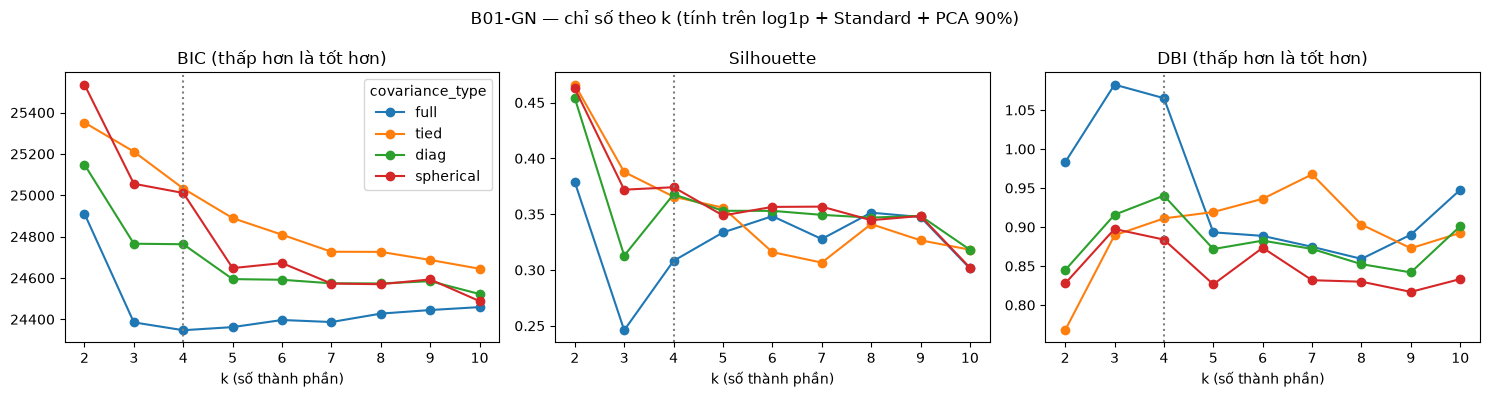

Silhouette cao nhất: {'covariance_type': 'tied', 'k': 2, 'Silhouette': 0.4660691766394036, 'min_cluster': 1005}


,k,BIC,AIC,Silhouette,DBI,CHI,min_cluster,converged
0,2,24910.8534,24840.7545,0.3787,0.9830,3189.3778,2158,True
1,3,24384.9918,24276.6571,0.2460,1.0825,2272.2991,882,True
2,4,24347.1145,24200.5440,0.3082,1.0652,2747.5769,838,True
3,5,24362.1096,24177.3034,0.3336,0.8932,3618.1038,223,True
4,6,24396.5511,24173.5091,0.3482,0.8886,3786.0437,253,True
5,7,24386.6986,24125.4208,0.3277,0.8746,3592.6526,212,True
6,8,24427.4100,24127.8964,0.3514,0.8592,3722.4692,178,True
7,9,24444.7478,24106.9984,0.3475,0.8902,3568.6951,150,True
8,10,24458.8476,24082.8625,0.3013,0.9478,3323.9217,78,True


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["BIC", "Silhouette", "DBI"]):
    for cov in COV_TYPES:
        s = res[res["covariance_type"] == cov]
        ax.plot(s["k"], s[col], marker="o", label=cov)
    ax.axvline(int(best["k"]), color="gray", ls=":")
    ax.set_xlabel("k (số thành phần)"); ax.set_title(col + (" (thấp hơn là tốt hơn)" if col in ("BIC", "DBI") else ""))
axes[0].legend(title="covariance_type")
plt.suptitle("B01-GN — chỉ số theo k (tính trên log1p + Standard + PCA 90%)")
plt.tight_layout(); fig.savefig(FIG / "gmm_metrics.png", dpi=150, bbox_inches="tight"); plt.show()

print("Silhouette cao nhất:", res.loc[res["Silhouette"].idxmax(), ["covariance_type", "k", "Silhouette", "min_cluster"]].to_dict())
res[res["covariance_type"] == best["covariance_type"]].drop(columns="covariance_type").round(4)

**Nhận xét:** BIC thấp nhất ở **`full`, k = 4** (24.347,1), cụm nhỏ nhất 838 khách. BIC của `full` giảm từ k = 2 (24.910,9) đến k = 4 rồi tăng lại (24.362,1 ở k = 5): có cực tiểu ở giữa lưới, không chạm biên k = 10. Chênh lệch BIC giữa k = 3–7 chỉ khoảng 24.347–24.397 nên k = 4 hơn k lân cận không nhiều. `diag`, `tied`, `spherical` đều có BIC thấp nhất ở biên k = 10 nhưng vẫn cao hơn `full` k = 4 (24.522 / 24.644 / 24.488). Silhouette cao nhất (0,466) ở `tied`, k = 2, không dùng để chọn vì GMM chọn theo BIC.

## Train mô hình cuối

In [7]:
model = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scaler", StandardScaler()),
                  ("pca", PCA(n_components=n_pc, svd_solver="full")),
                  ("gmm", GaussianMixture(n_components=int(best["k"]), covariance_type=best["covariance_type"],
                                          n_init=N_INIT, max_iter=MAX_ITER, tol=TOL, reg_covar=REG_COVAR,
                                          init_params=INIT_PARAMS, random_state=RANDOM_STATE))]).fit(X)
gm = model["gmm"]
assert np.allclose(model[:-1].transform(X), Z)                       # pipeline cho đúng không gian đã quét
labels, proba = gm.predict(Z), gm.predict_proba(Z)
assert (labels == fit_gmm(Z, best["k"], best["covariance_type"]).predict(Z)).all()

print("Số khách theo cụm:", np.bincount(labels).tolist())
print("Hội tụ:", gm.converged_, "| số vòng EM:", gm.n_iter_, "| BIC:", round(gm.bic(Z), 1))
print("Silhouette:", round(silhouette_score(Z, labels), 4), "| DBI:", round(davies_bouldin_score(Z, labels), 4),
      "| CHI:", round(calinski_harabasz_score(Z, labels), 1))
soft = int((proba.max(axis=1) < 0.8).sum())
print(f"Khách có xác suất cụm cao nhất < 0,8: {soft} ({soft / len(X):.1%})")

Số khách theo cụm: [1021, 838, 959, 1509]
Hội tụ: True | số vòng EM: 29 | BIC: 24347.1


Silhouette: 0.3082 | DBI: 1.0652 | CHI: 2747.6
Khách có xác suất cụm cao nhất < 0,8: 1973 (45.6%)


**Nhận xét:** 4 cụm khá cân đối (838–1.509 khách, 19,4–34,9%), hội tụ sau 29 vòng EM; Silhouette 0,3082, DBI 1,0652. Ranh giới giữa các cụm **mờ**: 1.973 khách (45,6%) có xác suất cụm cao nhất dưới 0,8, nên nên xem đây là phân khúc "mềm" chứ không phải các nhóm tách bạch.

## Hồ sơ cụm

Mô tả bằng trung vị RFM **trên thang gốc** (không phải log). `Monetary_share_pct` là tỷ trọng tổng Monetary của cụm.

In [8]:
prof = X.assign(cluster=labels, max_proba=proba.max(axis=1)).groupby("cluster").agg(
    customers=("Monetary", "size"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"),
    Monetary_sum=("Monetary", "sum"),
    max_proba_mean=("max_proba", "mean"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum")
prof.round(2)

,customers,Recency,Frequency,Monetary,max_proba_mean,customer_share_pct,Monetary_share_pct
cluster,,,,,,,
0,1021,47.0,1.0,291.48,0.73,23.60,3.85
1,838,6.0,6.0,2071.43,0.82,19.37,58.82
2,959,250.0,1.0,296.25,0.83,22.16,4.06
3,1509,50.0,4.0,1324.16,0.78,34.87,33.27


**Nhận xét** (tên nhóm chỉ là cách gọi gợi ý từ trung vị RFM, chưa phải kết luận của mô hình):
- Cụm 1 (838 khách, 19,4%): Recency 6, Frequency 6, Monetary ≈ 2.071 → **mua gần đây, thường xuyên, chi tiêu cao**; chiếm 58,8% tổng Monetary.
- Cụm 3 (1.509 khách, 34,9%): Recency 50, Frequency 4, Monetary ≈ 1.324 → **khách khá thường xuyên, chi tiêu khá**; chiếm 33,3% Monetary.
- Cụm 0 (1.021 khách, 23,6%): Recency 47, Frequency 1, Monetary ≈ 292 → **mới mua một lần, còn khá gần đây**.
- Cụm 2 (959 khách, 22,2%): Recency 250, Frequency 1, Monetary ≈ 296 → **mua một lần, lâu chưa quay lại**.

Hai cụm mua một lần (0 và 2) cùng chi tiêu thấp, khác nhau chủ yếu ở Recency; hai cụm còn lại tách theo mức chi tiêu và tần suất. Hai cụm có giá trị cao (1 và 3) cộng lại 54,3% khách nhưng 92,1% Monetary.

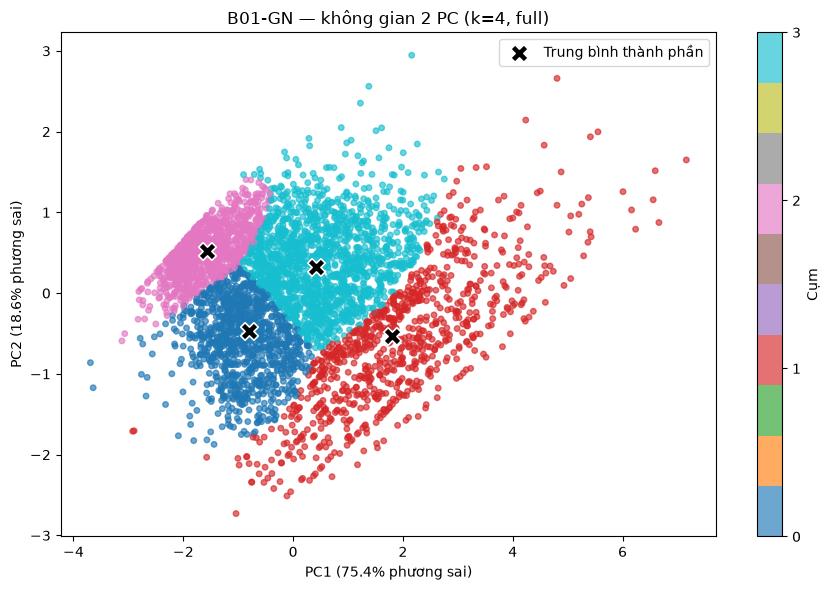

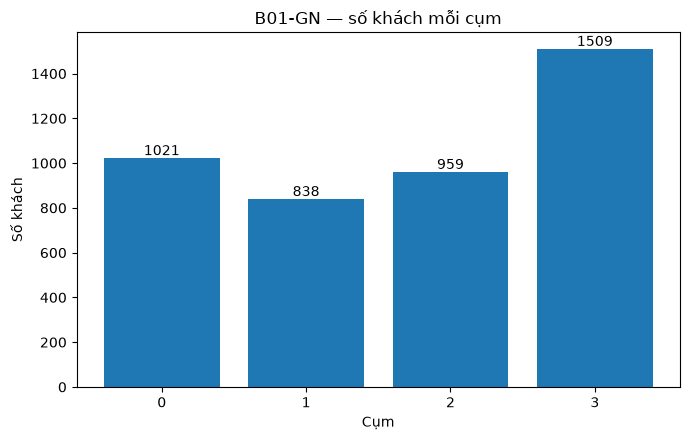

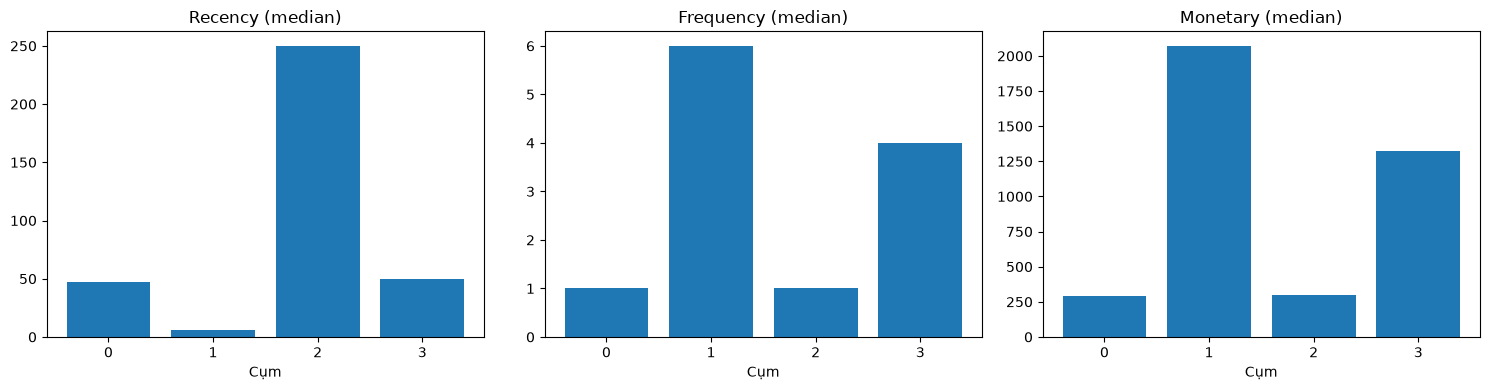

In [9]:
# Hình 1: các thành phần trong không gian 2 PC (đúng không gian mô hình được fit)
centers = gm.means_
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=16, alpha=0.65, rasterized=True)
ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=160, edgecolors="white", linewidths=1.2,
           label="Trung bình thành phần")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} phương sai)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} phương sai)")
ax.set_title(f"B01-GN — không gian {n_pc} PC (k={gm.n_components}, {gm.covariance_type})")
ax.legend(loc="best"); fig.colorbar(sc, ax=ax, label="Cụm", ticks=sorted(np.unique(labels)))
fig.tight_layout(); fig.savefig(FIG / "gmm_clusters_pca.png", dpi=150, bbox_inches="tight"); plt.show()

# Hình 2: số khách mỗi cụm
cnt = pd.Series(labels).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(cnt.index.astype(str), cnt.values); ax.bar_label(bars)
ax.set_xlabel("Cụm"); ax.set_ylabel("Số khách"); ax.set_title("B01-GN — số khách mỗi cụm")
plt.tight_layout(); fig.savefig(FIG / "gmm_cluster_distribution.png", dpi=150); plt.show()

# Hình 3: trung vị RFM từng cụm (thang gốc)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, FEATURES):
    ax.bar(prof.index.astype(str), prof[f]); ax.set_title(f + " (median)"); ax.set_xlabel("Cụm")
plt.tight_layout(); fig.savefig(FIG / "gmm_rfm_comparison.png", dpi=150); plt.show()

**Nhận xét:** Trong không gian 2 PC, các cụm là những vùng liền kề nhau, không có khoảng trống giữa chúng (cụm 0, 2 và 3 gặp nhau gần gốc tọa độ; cụm 1 kéo thành đuôi dài về phía PC1 lớn), khớp với tỷ lệ khách có xác suất cụm < 0,8 ở trên. Biểu đồ trung vị cho thấy hai trục tách cụm: Recency (cụm 2 xa nhất) và Frequency/Monetary (cụm 1 cao nhất).

## Đối chiếu A01 và cấu hình của Thuận

Ba việc, tất cả tính lại bằng chính code ở trên: (1) dựng lại A01 (StandardScaler → PCA 90% → GMM, cùng lưới và quy tắc) để so cùng điều kiện; (2) kiểm tra pipeline này khớp bảng của Thuận; (3) tái hiện cấu hình B của Thuận (log1p + Standard, **không PCA**) để thấy riêng tác động của PCA ở B01.

In [10]:
# (1) A01 dựng lại: RFM thô -> Standard -> PCA 90% -> GMM
Xa = StandardScaler().fit_transform(X)
cum_a = np.cumsum(PCA(svd_solver="full").fit(Xa).explained_variance_ratio_)
n_pc_a = int(np.searchsorted(cum_a, PCA_VAR) + 1)
Z_a01 = PCA(n_components=n_pc_a, svd_solver="full").fit_transform(Xa)
res_a01 = sweep(Z_a01)
best_a01 = select(res_a01, len(X))
gm_a01 = fit_gmm(Z_a01, best_a01["k"], best_a01["covariance_type"])
labels_a01 = gm_a01.predict(Z_a01)
print(f"A01 dựng lại: {n_pc_a}/3 PC | chọn {best_a01['covariance_type']}, k={int(best_a01['k'])}, "
      f"BIC={best_a01['BIC']:,.1f}, Silhouette={best_a01['Silhouette']:.4f}, cụm nhỏ nhất={int(best_a01['min_cluster'])}")
print("Kích thước cụm A01:", np.bincount(labels_a01).tolist())
print("ARI giữa cách chia A01 và B01:", round(adjusted_rand_score(labels_a01, labels), 4))

A01 dựng lại: 3/3 PC | chọn full, k=5, BIC=718.9, Silhouette=0.1349, cụm nhỏ nhất=49
Kích thước cụm A01: [2129, 1536, 503, 110, 49]
ARI giữa cách chia A01 và B01: 0.288


In [11]:
# (2) và (3): đọc bảng của Thuận để đối chiếu
th = openpyxl.load_workbook(find("notebooks/03_clustering_eval/14-11-2026-thuan-gmm-rfm/Working_details_GMM_RFM.xlsx"),
                            data_only=True)
th_bic = {(r[0], r[1]): r[2] for r in th["GMM_RFM"].iter_rows(min_row=15, max_row=50, max_col=3, values_only=True) if r[0]}
chk = res_a01.assign(BIC_thuan=[th_bic[(c, k)] for c, k in zip(res_a01["covariance_type"], res_a01["k"])])
chk["abs_diff"] = (chk["BIC"] - chk["BIC_thuan"]).abs()
print("(2) Lệch BIC lớn nhất giữa A01 dựng lại và bảng cấu hình A của Thuận, theo covariance_type:")
print(chk.groupby("covariance_type")["abs_diff"].max().round(3).to_string())

# (3) Cấu hình B của Thuận: log1p + Standard, không PCA, full, k = 10
sb = th["So_sanh_cau_hinh"]
th_b = {"BIC": sb["D3"].value, "Silhouette": sb["E3"].value, "DBI": sb["F3"].value, "CHI": sb["G3"].value}
gm_b = fit_gmm(X_scaled, 10, "full"); lab_b = gm_b.predict(X_scaled)
mine_b = {"BIC": round(gm_b.bic(X_scaled), 1), "Silhouette": round(silhouette_score(X_scaled, lab_b), 4),
          "DBI": round(davies_bouldin_score(X_scaled, lab_b), 4), "CHI": round(calinski_harabasz_score(X_scaled, lab_b), 1)}
print("\n(3) Tái hiện cấu hình B của Thuận (log1p + Standard, không PCA, full, k=10):")
print("   Bảng Thuận:", th_b)
print("   Tính lại  :", mine_b)
print("   Khớp:", th_b == mine_b)

(2) Lệch BIC lớn nhất giữa A01 dựng lại và bảng cấu hình A của Thuận, theo covariance_type:
covariance_type
diag         23751.614
full             0.005
spherical        0.005
tied             0.005



(3) Tái hiện cấu hình B của Thuận (log1p + Standard, không PCA, full, k=10):
   Bảng Thuận: {'BIC': -9362.1, 'Silhouette': 0.1091, 'DBI': 3.1674, 'CHI': 1140.9}
   Tính lại  : {'BIC': -9362.1, 'Silhouette': 0.1091, 'DBI': 3.1674, 'CHI': 1140.9}
   Khớp: True


In [12]:
def line(name, cfg, n_components, Zs, gm_):
    lab = gm_.predict(Zs)
    return {"Thí nghiệm": name, "Cấu hình": cfg, "Số PC": n_components, "covariance": gm_.covariance_type,
            "k": gm_.n_components, "BIC": round(gm_.bic(Zs), 1),
            "Silhouette": round(silhouette_score(Zs, lab), 4), "DBI": round(davies_bouldin_score(Zs, lab), 4),
            "CHI": round(calinski_harabasz_score(Zs, lab), 1),
            "Kích thước cụm": sorted(np.bincount(lab).tolist(), reverse=True),
            "Silhouette trên không gian B01": round(silhouette_score(Z, lab), 4)}

cmp = pd.DataFrame([
    line("A01-GN (dựng lại)", "Standard + PCA 90%", n_pc_a, Z_a01, gm_a01),
    line("B01-GN", "log1p + Standard + PCA 90%", n_pc, Z, gm),
    line("Thuận B (tham chiếu)", "log1p + Standard, không PCA", 3, X_scaled, gm_b),
])
cmp

,Thí nghiệm,Cấu hình,Số PC,covariance,k,BIC,Silhouette,DBI,CHI,Kích thước cụm,Silhouette trên không gian B01
0,A01-GN (dựng lại),Standard + PCA 90%,3,full,5,718.9,0.1349,1.9633,607.7,"[2129, 1536, 503, 110, 49]",0.2797
1,B01-GN,log1p + Standard + PCA 90%,2,full,4,24347.1,0.3082,1.0652,2747.6,"[1509, 1021, 959, 838]",0.3082
2,Thuận B (tham chiếu),"log1p + Standard, không PCA",3,full,10,-9362.1,0.1091,3.1674,1140.9,"[877, 829, 627, 501, 405, 392, 238, 219, 172, 67]",0.0953


**Nhận xét:**
- **Pipeline khớp nhóm:** BIC dựng lại của A01 trùng bảng của Thuận (lệch tối đa 0,005, chỉ do làm tròn) ở `full`, `tied`, `spherical` với mọi k, vì ba loại này không đổi khi xoay trục. `diag` thì lệch lớn vì không bất biến khi xoay: cấu hình A của Thuận (không PCA) chọn `diag`, k = 6, còn A01 có PCA chọn `full`, k = 5. Tái hiện cấu hình B của Thuận cũng khớp đến từng chữ số (BIC −9.362,1; Silhouette 0,1091; DBI 3,1674; CHI 1.140,9).
- **B01 khác A01 thật:** ARI giữa hai cách chia chỉ 0,288. A01 chia thành khối lớn (2.129 và 1.536 khách) cùng các cụm nhỏ (503, 110, 49 khách); B01 chia 4 cụm cân đối (cụm nhỏ nhất 838 khách).
- **Mức hơn nhau về độ chặt của cụm là nhỏ:** trên cùng không gian của B01, Silhouette là 0,3082 (B01) so với 0,2797 (A01). Lợi thế chính của B01 là **cụm cân đối, đọc được**, chứ không phải cụm chặt hơn nhiều. Cấu hình B của Thuận (không PCA) chỉ đạt 0,0953 trên không gian này.
- **Không so BIC và Silhouette trực tiếp giữa các dòng** vì mỗi dòng được tính trên không gian khác (số chiều, biến đổi); cột cuối là phép so cùng không gian.

## Lưu kết quả

In [13]:
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels, "max_proba": proba.max(axis=1).round(4)}) \
    .to_csv(OUT / "gmm_b01_labels.csv", index=False)
joblib.dump(model, "gmm_model.pkl")

params = {"experiment": "B01-GN", "features": FEATURES, "transform": "log1p", "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc, "pca_variance_kept": float(cum[n_pc - 1]),
          "covariance_type": best["covariance_type"], "k": int(best["k"]),
          "bic": float(best["BIC"]), "aic": float(best["AIC"]), "silhouette": float(best["Silhouette"]),
          "dbi": float(best["DBI"]), "chi": float(best["CHI"]), "min_cluster": int(best["min_cluster"]),
          "converged": bool(gm.converged_), "n_iter": int(gm.n_iter_), "gmm_params": gm.get_params()}
json.dump(params, open("gmm_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in Path(".").iterdir() if p.is_file()), sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['Working_details_GMM_B01.xlsx', 'gmm_b01.ipynb', 'gmm_model.pkl', 'gmm_params.json'] ['gmm_b01_labels.csv']


## Working_details

Ghi bảng tóm tắt theo bố cục `Working_details_GMM_RFM.xlsx` của Thuận: sheet chính (thiết lập, bảng quét `covariance_type × k`, bảng cụm) và sheet `So_sanh_cau_hinh`. Không có sheet làm sạch vì dùng file đã làm sạch của nhóm.

In [14]:
from openpyxl import Workbook
from openpyxl.styles import Font

wb = Workbook(); ws = wb.active; ws.title = "GMM_B01"
B = Font(name="Calibri", bold=True)
def put(sheet, cell, value, bold=False, fmt=None):
    sheet[cell] = value
    sheet[cell].font = B if bold else Font(name="Calibri")
    if fmt: sheet[cell].number_format = fmt

n = len(X)
put(ws, "A1", "THÍ NGHIỆM GMM — B01 (RFM, log1p, Standard, PCA 90%)", bold=True)
put(ws, "A2", "Trạng thái", bold=True)
put(ws, "B2", "Đã chạy xong; BIC/AIC/Silhouette/DBI/CHI tính trên Z (không gian log1p + Standard + PCA 90%)")
for c, v in zip("ABDE", ["Thiết lập", "Giá trị", "Tham số khác", "Giá trị"]): put(ws, f"{c}4", v, bold=True)
left = [("Feature", "Recency, Frequency, Monetary"), ("Dữ liệu train", f"Z (log1p → Standard → PCA 90%, {n_pc} PC)"),
        ("Nguồn dữ liệu", "12-11-2026-hieu-kmeans/data/customer_features.csv"),
        ("covariance_type", best["covariance_type"]), ("k được chọn", int(best["k"])),
        ("random_state", RANDOM_STATE), ("n_init", N_INIT), ("init_params", INIT_PARAMS)]
right = [("max_iter", MAX_ITER), ("tol", TOL), ("reg_covar", REG_COVAR), ("Tổng khách hàng", int(n)),
         ("Số vòng EM", int(gm.n_iter_)), ("Hội tụ", bool(gm.converged_)),
         ("Quy tắc chọn", "BIC thấp nhất, mỗi cụm >= 1% số khách"),
         ("PCA", f"{n_pc}/3 PC, phương sai {cum[n_pc-1]:.2%}")]
for i, ((a, b), (d, e)) in enumerate(zip(left, right), start=5):
    put(ws, f"A{i}", a); put(ws, f"B{i}", b); put(ws, f"D{i}", d); put(ws, f"E{i}", e)

hdr = ["covariance_type", "k", "BIC", "AIC", "Silhouette", "DBI", "CHI", "Cụm nhỏ nhất", "Nhận xét"]
for c, v in zip("ABCDEFGHI", hdr): put(ws, f"{c}14", v, bold=True)
for i, r in enumerate(res.itertuples(), start=15):
    if r.covariance_type == best["covariance_type"] and r.k == int(best["k"]): note = "được chọn"
    elif not r.converged: note = "không hội tụ"
    elif r.min_cluster < MIN_CLUSTER_FRAC * n: note = "loại: cụm nhỏ nhất < 1% số khách"
    else: note = ""
    vals = [r.covariance_type, int(r.k), round(r.BIC, 2), round(r.AIC, 2), round(r.Silhouette, 4), round(r.DBI, 4),
            round(r.CHI, 2), int(r.min_cluster), note]
    fmts = [None, None, "0.00", "0.00", "0.0000", "0.0000", "0.00", None, None]
    for c, v, f in zip("ABCDEFGHI", vals, fmts): put(ws, f"{c}{i}", v, fmt=f)

r0 = 15 + len(res) + 1
for c, v in zip("ABCDEFGH", ["Cụm", "Mô tả (so với trung vị chung)", "Số khách", "Tỷ lệ (%)", "Recency (median)",
                              "Frequency (median)", "Monetary (median)", "Tỷ trọng Monetary (%)"]):
    put(ws, f"{c}{r0}", v, bold=True)
med = X.median()
def mo_ta(p):
    return ("Recency xa (lâu chưa mua)" if p["Recency"] > med["Recency"] else "Recency gần") + ", " + \
           ("Frequency cao" if p["Frequency"] > med["Frequency"] else "Frequency thấp") + ", " + \
           ("Monetary cao" if p["Monetary"] > med["Monetary"] else "Monetary thấp")
for j, (cl, p) in enumerate(prof.iterrows(), start=r0 + 1):
    put(ws, f"A{j}", int(cl)); put(ws, f"B{j}", mo_ta(p)); put(ws, f"C{j}", int(p["customers"]))
    put(ws, f"D{j}", float(p["customer_share_pct"]), fmt="0.00"); put(ws, f"E{j}", float(p["Recency"]))
    put(ws, f"F{j}", float(p["Frequency"])); put(ws, f"G{j}", float(p["Monetary"]), fmt="0.00")
    put(ws, f"H{j}", float(p["Monetary_share_pct"]), fmt="0.00")
for col, w in zip("ABCDEFGHI", [16, 22, 17, 19, 20, 21, 25, 22, 13]): ws.column_dimensions[col].width = w
ws.freeze_panes = "A5"

ws2 = wb.create_sheet("So_sanh_cau_hinh")
for c, v in zip("ABCDEFGHIJ", ["Thí nghiệm", "Cấu hình", "Số PC", "covariance", "k", "BIC", "Silhouette", "DBI", "CHI",
                               "Silhouette trên không gian B01"]): put(ws2, f"{c}1", v, bold=True)
for i, r in enumerate(cmp.itertuples(index=False), start=2):
    vals = [r[0], r[1], int(r[2]), r[3], int(r[4]), float(r[5]), float(r[6]), float(r[7]), float(r[8]), float(r[10])]
    for c, v in zip("ABCDEFGHIJ", vals): put(ws2, f"{c}{i}", v)
    put(ws2, f"K{i}", "kích thước cụm: " + str(r[9]))
put(ws2, "A6", "BIC và Silhouette tính trên không gian khác nhau của từng dòng nên không so trực tiếp; cột J là phép so cùng không gian (của B01).")
put(ws2, "A7", f"ARI giữa cách chia A01 (dựng lại) và B01: {adjusted_rand_score(labels_a01, labels):.4f}")
for col, w in zip("ABCDEFGHIJK", [24, 30, 8, 12, 6, 12, 12, 10, 10, 30, 40]): ws2.column_dimensions[col].width = w

wb.save("Working_details_GMM_B01.xlsx")
print("Đã lưu Working_details_GMM_B01.xlsx")

Đã lưu Working_details_GMM_B01.xlsx


## Kết luận B01-GN

- **log1p đổi hẳn kết quả so với A01** (ARI = 0,288): thay vì khối lớn kèm vài cụm ngoại lai nhỏ (49–110 khách), GMM chọn `full`, **k = 4** với 4 cụm cân đối 838–1.509 khách, hội tụ, không chạm biên lưới.
- **PCA 90% ở B01 thực sự giảm chiều** (3 → 2 PC, giữ 94,01%), khác A01/A02/A04 nơi PCA chỉ xoay trục. Pipeline khớp bảng của Thuận (A và B), nên kết quả này so sánh được với phần GMM của nhóm.
- **Đọc được thành 4 phân khúc gợi ý:** khách mua gần, thường xuyên, chi nhiều (19,4% khách, 58,8% Monetary); khách khá thường xuyên (34,9%); mua một lần còn gần (23,6%); mua một lần lâu chưa quay lại (22,2%).
- **Giới hạn:** ranh giới mờ (45,6% khách có xác suất cụm cao nhất < 0,8); chênh BIC giữa k = 3–7 nhỏ nên k = 4 không phải lựa chọn nổi bật; Silhouette trên cùng không gian chỉ hơn A01 một chút (0,308 so với 0,280). B01 cũng không còn tách riêng nhóm khách ngoại lai cực nhỏ như A01.
- **Bước kế tiếp:** B02 (chỉ log F, M, giữ nguyên Recency) và B04 (log1p + MinMax) so với kết quả này.